# Choosing barriers for a mean-reverting strategy

A centered Ornstein-Uhlenbeck process moves toward zero while receiving continuous random shocks:

$$
dY_t=-\theta Y_t\,dt+\sigma\,dW_t,
\qquad
\operatorname{Var}_{\infty}(Y_t)=\frac{\sigma^2}{2\theta},
\qquad
h_{1/2}=\frac{\log 2}{\theta}.
$$

Here, $Y_t$ is the deviation from its long-run mean, $\theta>0$ is the speed of mean reversion, $\sigma>0$ is the shock scale per square-root time unit, $W_t$ is standard Brownian motion, $\operatorname{Var}_{\infty}(Y_t)$ is the stationary variance, and $h_{1/2}$ is the half-life of a deviation.

In [1]:
using CSV, DataFrames, Dates, Statistics, LinearAlgebra, TOML, Plots
include(joinpath("..","support","BookSupport.jl"))
using .BookSupport
using .BookSupport: palette
configure_plots!()
input_root = normpath(joinpath("..","data","chapter22_ou_random_inputs"))
using RiskLabAI
@assert pkgversion(RiskLabAI) == v"1.1.0"
using RiskLabAI.Backtest: theta_from_half_life, stationary_std, fit_ornstein_uhlenbeck, hit_upper_probability, mean_exit_time, optimal_ou_trading_rule, ou_rule_metrics
source_path = joinpath(book_root(),"data","public","fred","SP500_2014-01-02_2025-12-31.csv")
raw = CSV.read(source_path,DataFrame;missingstring=["","."])
dropmissing!(raw,:SP500)
sort!(raw,:observation_date)
dates,prices = Date.(raw.observation_date),Float64.(raw.SP500)
logs = log.(prices)
public_deviation = [logs[index]-mean(logs[index-59:index]) for index in 60:length(logs)]
standardized_deviation = (public_deviation.-mean(public_deviation))./std(public_deviation)
deviation_dates = dates[60:end]
public_fit = fit_ornstein_uhlenbeck(standardized_deviation;dt=1.)
paths = output_paths("22_position_sizing")
data_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31"
violet,muted = "#C084FC","#9CA3AF"
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter19-"*replace(name,"_"=>"-"))
isclose(x,y;atol=1e-8,rtol=1e-5) = abs(x-y)<=atol+rtol*abs(y)
function primitive(name)
    specification = TOML.parsefile(joinpath(input_root,"inputs.toml"))[name]
    path = joinpath(input_root,specification["path"])
    values = Array{Float64}(undef,Tuple(specification["shape"]))
    read!(path,values)
    return values
end
function simulate_ou(theta,sigma,n_paths,n_steps,dt,draws;y_start=0.)
    @assert size(draws)==(n_paths,n_steps)
    rho = exp(-theta*dt)
    innovation_scale = sigma*sqrt((1-rho^2)/(2theta))
    state = fill(float(y_start),n_paths)
    paths = Matrix{Float64}(undef,n_paths,n_steps)
    for location in 1:n_steps
        state = rho.*state .+innovation_scale.*draws[:,location]
        paths[:,location] = state
    end
    return paths
end
function monte_carlo_return_rate(paths,entry_gap,profit_take,stop_loss,cost,dt)
    upper,lower = -entry_gap+profit_take,-entry_gap-stop_loss
    gain_sum,time_sum,completed = 0.,0.,0
    for row in axes(paths,1)
        for step in axes(paths,2)
            value = paths[row,step]
            if value>=upper || value<=lower
                gain_sum += value>=upper ? profit_take : -stop_loss
                time_sum += step*dt
                completed += 1
                break
            end
        end
    end
    return completed>0 ? (gain_sum/completed-cost)/(time_sum/completed) : -Inf
end
function row_major_argmax(values)
    index = argmax(permutedims(values))
    return CartesianIndex(index[2],index[1])
end


row_major_argmax (generic function with 1 method)

## Public Mean-Reverting Deviation

Discrete daily observations are fitted through a first-order relation:

$$
Y_t=a+\rho Y_{t-1}+\varepsilon_t,
\qquad
\widehat\theta=-\log(\widehat\rho),
\qquad
\widehat\mu=\frac{\widehat a}{1-\widehat\rho}.
$$

Here, $Y_t$ is the standardized log-price deviation on day $t$, $a$ is the fitted intercept, $\rho\in(0,1)$ is the one-day persistence, $\varepsilon_t$ is the fitted innovation, $\widehat\theta$ is the estimated continuous mean-reversion speed for a one-day step, and $\widehat\mu$ is the estimated long-run mean.

Row,Field,Value
,String,String
1,Series,S&P 500
2,Provider,Federal Reserve Bank of St. Louis
3,Source,https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31
4,First deviation,2016-12-19
5,Last deviation,2025-12-31
6,Deviation definition,"Log price minus its sixty-day rolling mean, then standardized"


Row,Quantity,Value
,String,Float64
1,Public observations,2330.0
2,Deviation observations,2271.0
3,Rolling mean length,60.0
4,Persistence,0.961987
5,Mean-reversion speed,0.0387538
6,Shock scale,0.278229
7,Long-run mean,-0.00845977
8,Half-life in trading days,17.8859
9,Stationary standard deviation,0.999378


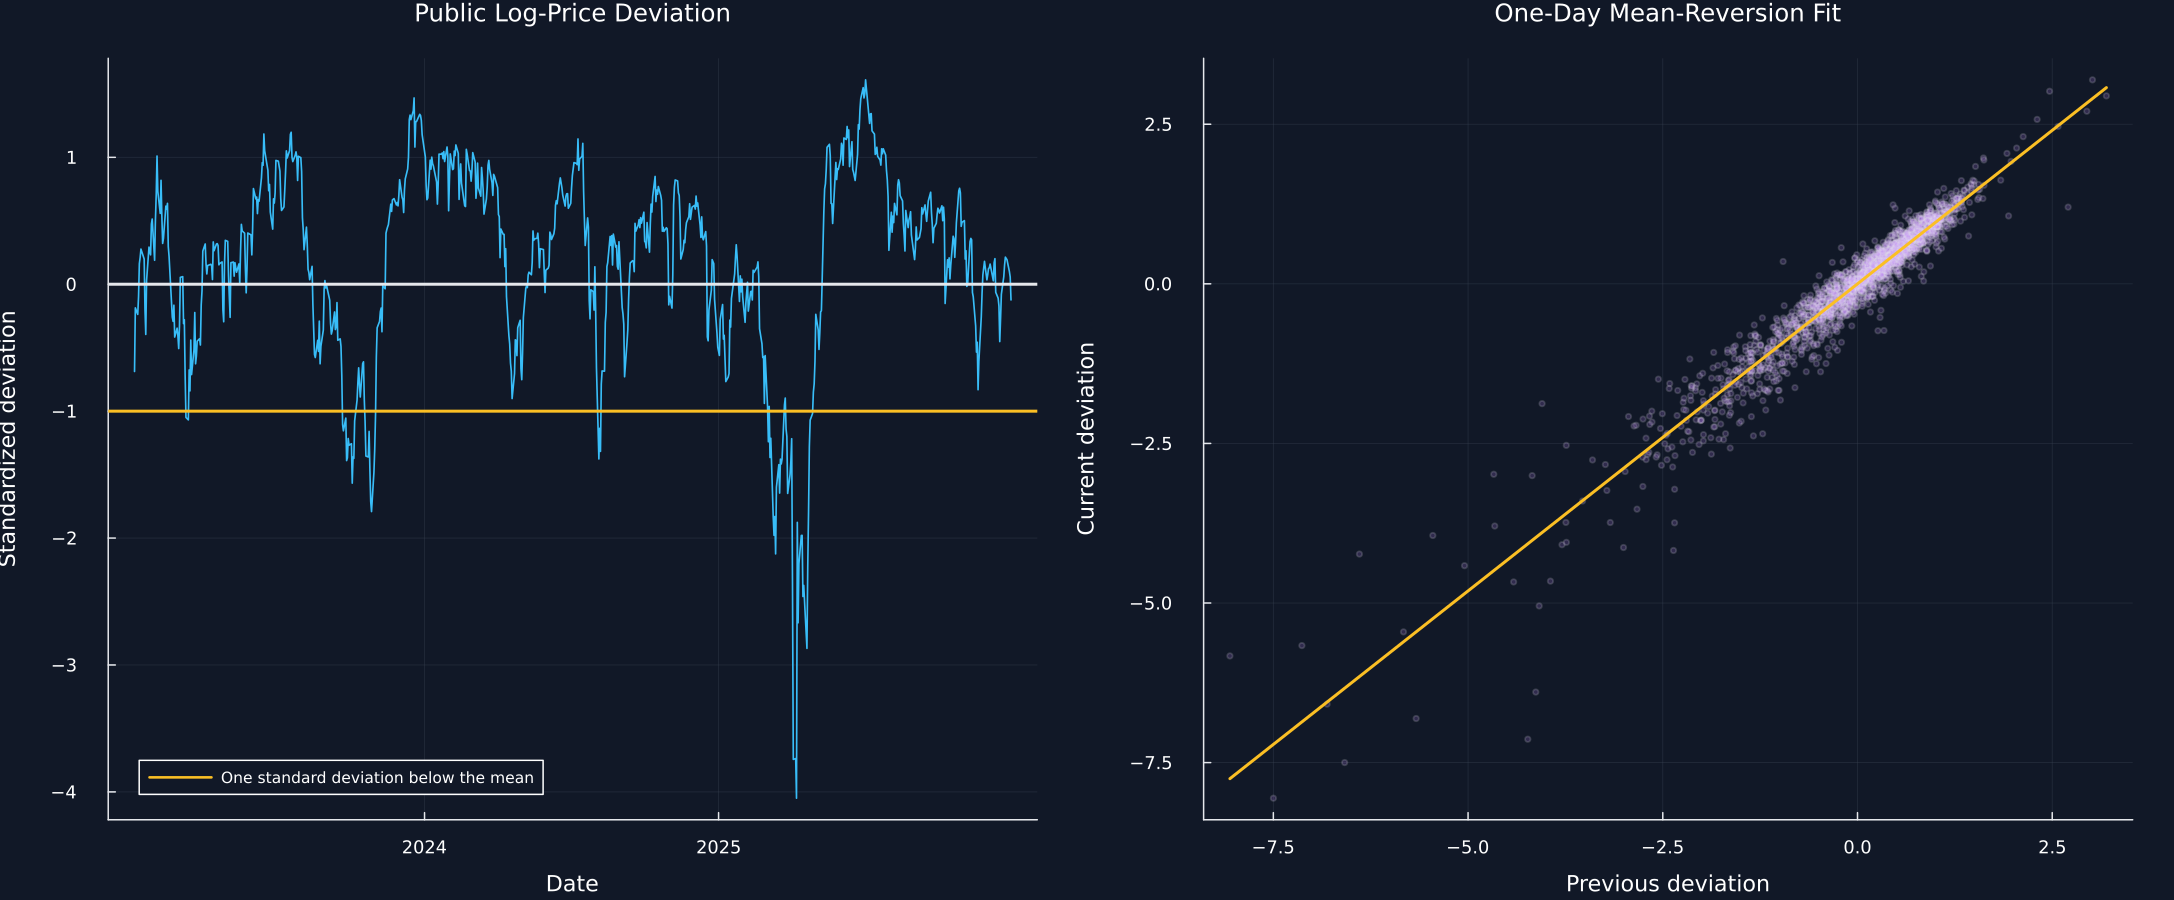

In [2]:
public_fit_table = DataFrame("Quantity"=>["Public observations","Deviation observations","Rolling mean length","Persistence","Mean-reversion speed","Shock scale","Long-run mean","Half-life in trading days","Stationary standard deviation","One-step fit R-squared"],"Value"=>[length(prices),length(standardized_deviation),60,public_fit.rho,public_fit.theta,public_fit.sigma,public_fit.mu,public_fit.half_life,public_fit.stationary_std,public_fit.r2])
public_deviation_provenance = DataFrame("Field"=>["Series","Provider","Source","First deviation","Last deviation","Deviation definition"],"Value"=>["S&P 500","Federal Reserve Bank of St. Louis",data_url,string(first(deviation_dates)),string(last(deviation_dates)),"Log price minus its sixty-day rolling mean, then standardized"])
table(public_deviation_provenance,"ou_data_provenance","Public observations used for the mean-reversion study.")
table(public_fit_table,"public_ou_fit","Fitted mean-reversion quantities for the public deviation.")
lagged,current = standardized_deviation[1:end-1],standardized_deviation[2:end]
fitted_current = public_fit.mu*(1-public_fit.rho).+public_fit.rho.*lagged
recent = length(standardized_deviation)-749:length(standardized_deviation)
tick_dates = filter(date->deviation_dates[first(recent)]<=date<=last(deviation_dates),Date.(year(deviation_dates[first(recent)]):year(last(deviation_dates)),1,1))
p1 = plot(Dates.value.(deviation_dates[recent]),standardized_deviation[recent];color=palette.cyan,linewidth=1.1,label="",title="Public Log-Price Deviation",xlabel="Date",ylabel="Standardized deviation",xticks=(Dates.value.(tick_dates),string.(year.(tick_dates))))
hline!(p1,[0.];color=palette.text,label="")
hline!(p1,[-1.];color=palette.amber,label="One standard deviation below the mean",legendfontsize=7)
p2 = scatter(lagged,current;color=violet,alpha=.18,markersize=2,label="",title="One-Day Mean-Reversion Fit",xlabel="Previous deviation",ylabel="Current deviation")
order = sortperm(lagged)
plot!(p2,lagged[order],fitted_current[order];color=palette.amber,label="")
save_figure(plot(p1,p2;layout=(1,2),size=(1450,600)),paths,"public_ou_fit")


## Evaluating barriers through exits and holding times

The upper-barrier probability and the expected net return per unit time are:

$$
u(y_0)=\frac{S(y_0)-S(a)}{S(b)-S(a)},
\qquad
S(x)=\int_0^x\exp\!\left(\frac{\theta s^2}{\sigma^2}\right)ds,
\qquad
R=\frac{g_+u-g_-(1-u)-c}{E[\tau]}.
$$

Here, $y_0=-e$ is the entry deviation, $e>0$ is the entry gap below the mean, $a=y_0-g_-$ is the lower barrier, $b=y_0+g_+$ is the upper barrier, $g_+>0$ is the profit amount, $g_->0$ is the loss amount, $S$ is the scale function, $u(y_0)$ is the chance of reaching the upper barrier first, $c\geq0$ is the cost per completed position, $\tau$ is the first exit time, and $R$ is expected net return per unit time.

Row,Quantity,Value
,String,Float64
1,Entry gap,1.0
2,Cost,0.02
3,Profit amount,0.273127
4,Loss amount,4.0
5,Upper-hit probability,0.999993
6,Expected gain,0.253097
7,Gain standard deviation,0.0113082
8,Expected holding time,4.98353
9,Expected return per unit time,0.0507866


Row,Profit amount,Loss amount,Upper-hit probability,Expected holding time,Expected return per unit time
,Float64,Float64,Float64,Float64,Float64
1,0.1,2.0,0.995442,1.62676,0.043294
2,0.2,2.0,0.991314,3.34563,0.0480898
3,0.3,2.0,0.987534,5.16507,0.0486591
4,0.4,2.0,0.984036,7.09474,0.0481604
5,0.5,2.0,0.980764,9.14568,0.0472256
6,0.6,2.0,0.977673,11.3306,0.0460656
7,0.7,2.0,0.974721,13.6639,0.0447709
8,0.8,2.0,0.971874,16.1625,0.0433872
9,0.9,2.0,0.969099,18.8457,0.0419399


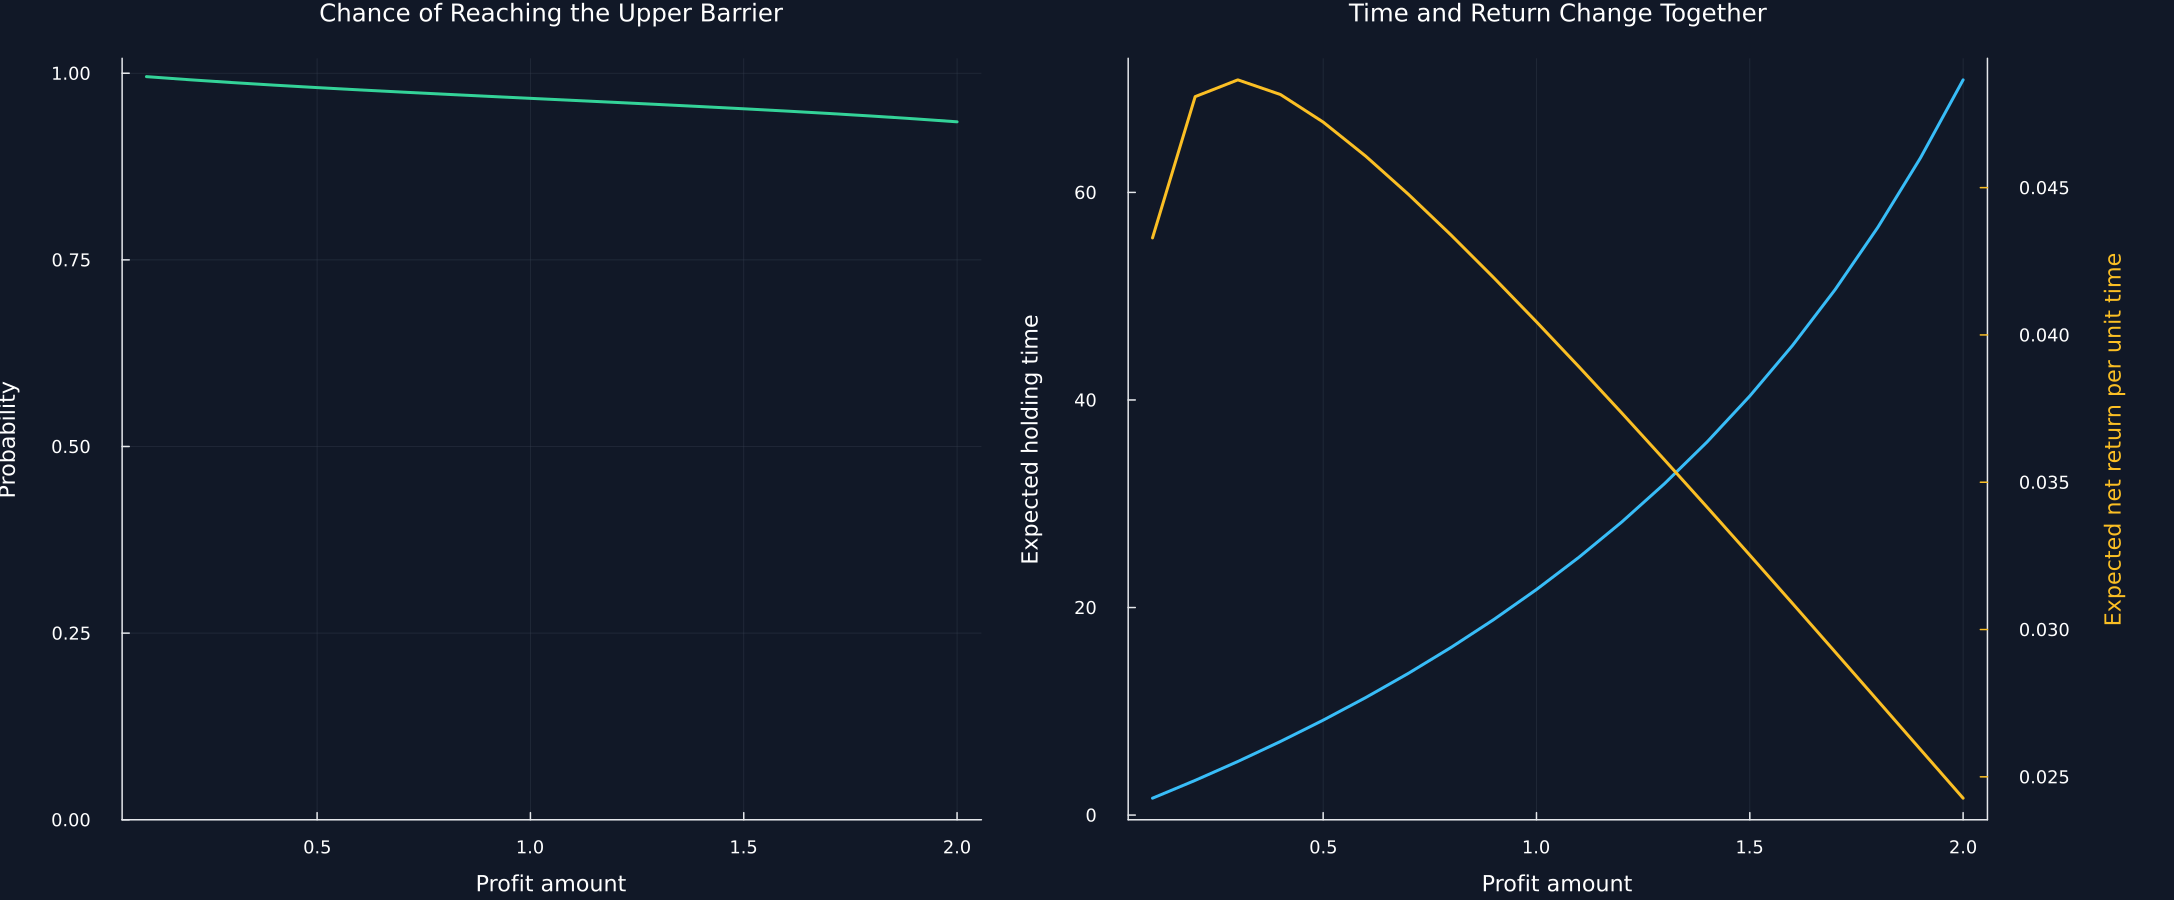

In [3]:
public_entry_gap,public_cost = 1.,.02
public_rule = optimal_ou_trading_rule(public_fit.theta,public_fit.sigma,public_entry_gap;cost=public_cost,bounds=(.1,4.))
public_rule_table = DataFrame("Quantity"=>["Entry gap","Cost","Profit amount","Loss amount","Upper-hit probability","Expected gain","Gain standard deviation","Expected holding time","Expected return per unit time","Time-scaled Sharpe"],"Value"=>[public_entry_gap,public_cost,public_rule.profit_take,public_rule.stop_loss,public_rule.hit_probability,public_rule.expected_gain,public_rule.std_gain,public_rule.expected_holding_time,public_rule.return_rate,public_rule.time_scaled_sharpe])
barrier_rows = NamedTuple[]
fixed_stop = 2.
for profit_take in range(.1,2.;length=20)
    values = ou_rule_metrics(profit_take,fixed_stop,public_fit.theta,public_fit.sigma,public_entry_gap,public_cost)
    push!(barrier_rows,(profit=profit_take,loss=fixed_stop,probability=values.hit_probability,time=values.expected_holding_time,rate=values.return_rate))
end
barrier_sensitivity = DataFrame(barrier_rows)
rename!(barrier_sensitivity,["Profit amount","Loss amount","Upper-hit probability","Expected holding time","Expected return per unit time"])
table(public_rule_table,"public_ou_rule","Illustrative public-data barrier rule within the declared search box.")
table(barrier_sensitivity,"barrier_sensitivity","Exit probability, holding time, and return rate as the upper barrier changes.")
p1 = plot(barrier_sensitivity[:,1],barrier_sensitivity[:,3];color=palette.green,label="",title="Chance of Reaching the Upper Barrier",xlabel="Profit amount",ylabel="Probability",ylims=(0,1.02))
p2 = plot(barrier_sensitivity[:,1],barrier_sensitivity[:,4];color=palette.cyan,label="",title="Time and Return Change Together",xlabel="Profit amount",ylabel="Expected holding time",right_margin=14Plots.mm)
plot!(twinx(p2),barrier_sensitivity[:,1],barrier_sensitivity[:,5];color=palette.amber,label="",ylabel="Expected net return per unit time",foreground_color_axis=palette.amber,foreground_color_guide=palette.amber,grid=false)
save_figure(plot(p1,p2;layout=(1,2),size=(1450,600)),paths,"barrier_probability_holding")


## Preliminary Monte Carlo Reproduction

Exact daily transitions generate controlled Ornstein-Uhlenbeck paths for the grid comparison:

$$
Y_{t+\Delta}=e^{-\theta\Delta}Y_t+\sigma\sqrt{\frac{1-e^{-2\theta\Delta}}{2\theta}}\,Z_{t+\Delta},
\qquad
Z_{t+\Delta}\overset{iid}{\sim}\mathcal N(0,1).
$$

Here, $\Delta$ is the time step, $e^{-\theta\Delta}$ is the one-step persistence, $Z_{t+\Delta}$ is a new standard normal shock, and the square-root term is the exact innovation scale. The path begins at the declared entry deviation.

Row,Quantity,Value
,String,Float64
1,Paths,8000.0
2,Steps per path,400.0
3,Grid points per side,16.0
4,Grid cells,256.0
5,Monte Carlo profit amount,0.75
6,Monte Carlo loss amount,2.0
7,Monte Carlo return rate,0.0442591
8,Analytical profit amount,0.535464
9,Analytical loss amount,4.0


Row,Surface,Profit amount,Loss amount,Expected return per unit time
,String,Float64,Float64,Float64
1,Monte Carlo grid,0.75,2.0,0.0442591
2,Analytical grid,0.5,4.0,0.0596909
3,Continuous analytical search,0.535464,4.0,0.0597723


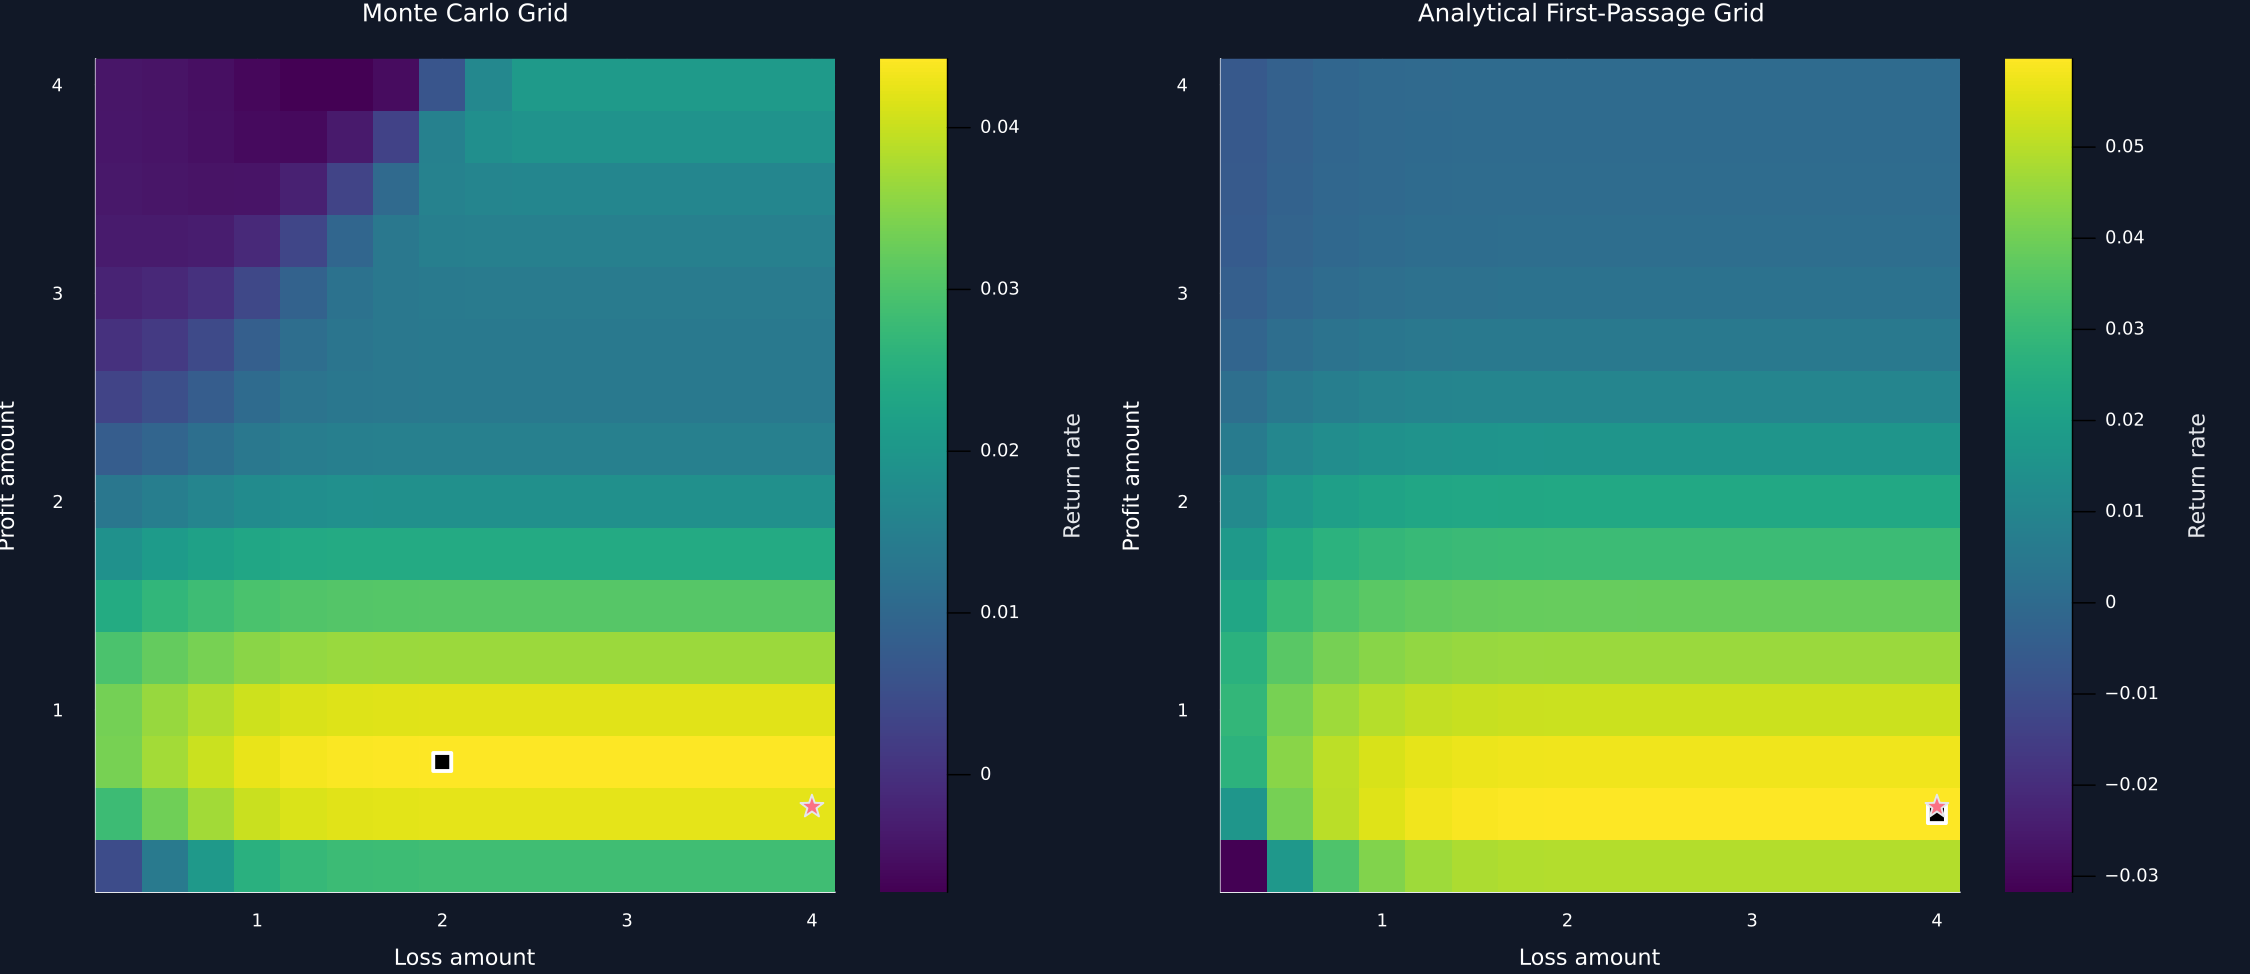

In [4]:
preliminary_theta = theta_from_half_life(10.)
preliminary_sigma,preliminary_entry_gap,preliminary_cost,preliminary_dt = .25,1.,.1,1.
preliminary_draws = primitive("preliminary")
preliminary_paths = simulate_ou(preliminary_theta,preliminary_sigma,8000,400,preliminary_dt,preliminary_draws;y_start=-preliminary_entry_gap)
preliminary_grid = collect(.25:.25:4.)
start_time = time_ns()
monte_carlo_surface = [monte_carlo_return_rate(preliminary_paths,preliminary_entry_gap,profit_take,stop_loss,preliminary_cost,preliminary_dt) for profit_take in preliminary_grid,stop_loss in preliminary_grid]
monte_carlo_seconds = (time_ns()-start_time)/1e9
monte_carlo_location = row_major_argmax(monte_carlo_surface)
repetitions = 50
function repeat_analytical(count,theta,sigma,gap,cost)
    start = time_ns()
    result = nothing
    for repetition in 1:count
        result = optimal_ou_trading_rule(theta,sigma,gap;cost,bounds=(.25,4.))
    end
    return result,(time_ns()-start)/1e9/count
end
preliminary_rule,analytical_seconds = repeat_analytical(repetitions,preliminary_theta,preliminary_sigma,preliminary_entry_gap,preliminary_cost)
analytical_surface = [ou_rule_metrics(profit_take,stop_loss,preliminary_theta,preliminary_sigma,preliminary_entry_gap,preliminary_cost).return_rate for profit_take in preliminary_grid,stop_loss in preliminary_grid]
analytical_location = row_major_argmax(analytical_surface)
preliminary_reproduction = DataFrame("Quantity"=>["Paths","Steps per path","Grid points per side","Grid cells","Monte Carlo profit amount","Monte Carlo loss amount","Monte Carlo return rate","Analytical profit amount","Analytical loss amount","Analytical return rate","Profit-amount difference","Grid spacing","Monte Carlo seconds","Analytical seconds per fit","Speed ratio"],"Value"=>[8000,400,length(preliminary_grid),length(preliminary_grid)^2,preliminary_grid[monte_carlo_location[1]],preliminary_grid[monte_carlo_location[2]],monte_carlo_surface[monte_carlo_location],preliminary_rule.profit_take,preliminary_rule.stop_loss,preliminary_rule.return_rate,abs(preliminary_rule.profit_take-preliminary_grid[monte_carlo_location[1]]),.25,monte_carlo_seconds,analytical_seconds,monte_carlo_seconds/analytical_seconds])
exact_grid_best = DataFrame("Surface"=>["Monte Carlo grid","Analytical grid","Continuous analytical search"],"Profit amount"=>[preliminary_grid[monte_carlo_location[1]],preliminary_grid[analytical_location[1]],preliminary_rule.profit_take],"Loss amount"=>[preliminary_grid[monte_carlo_location[2]],preliminary_grid[analytical_location[2]],preliminary_rule.stop_loss],"Expected return per unit time"=>[monte_carlo_surface[monte_carlo_location],analytical_surface[analytical_location],preliminary_rule.return_rate])
table(preliminary_reproduction,"preliminary_ou_reproduction","Reproduction of the preliminary Monte Carlo and analytical barrier comparison.")
table(exact_grid_best,"ou_grid_best","Best barrier pair on each controlled surface.")
p1 = heatmap(preliminary_grid,preliminary_grid,monte_carlo_surface;color=:viridis,title="Monte Carlo Grid",xlabel="Loss amount",ylabel="Profit amount",colorbar_title="Return rate",xlims=(.125,4.125),ylims=(.125,4.125))
scatter!(p1,[preliminary_grid[monte_carlo_location[2]]],[preliminary_grid[monte_carlo_location[1]]];markershape=:rect,markercolor=:transparent,markerstrokecolor=:white,markerstrokewidth=2,markersize=6,label="")
scatter!(p1,[preliminary_rule.stop_loss],[preliminary_rule.profit_take];markershape=:star5,color=palette.rose,markersize=8,label="")
p2 = heatmap(preliminary_grid,preliminary_grid,analytical_surface;color=:viridis,title="Analytical First-Passage Grid",xlabel="Loss amount",ylabel="Profit amount",colorbar_title="Return rate",xlims=(.125,4.125),ylims=(.125,4.125))
scatter!(p2,[preliminary_grid[analytical_location[2]]],[preliminary_grid[analytical_location[1]]];markershape=:rect,markercolor=:transparent,markerstrokecolor=:white,markerstrokewidth=2,markersize=6,label="")
scatter!(p2,[preliminary_rule.stop_loss],[preliminary_rule.profit_take];markershape=:star5,color=palette.rose,markersize=8,label="")
save_figure(plot(p1,p2;layout=(1,2),size=(1500,650)),paths,"ou_surface_comparison")


## Searching for barriers after costs

The barrier pair is chosen inside an explicitly bounded search region:

$$
(g_+^*,g_-^*)=\arg\max_{\ell\leq g_+,g_-\leq u}R(g_+,g_-;\theta,\sigma,e,c).
$$

Here, $R$ is the expected net return per unit time, $g_+$ and $g_-$ are the profit and loss amounts, $\theta$ and $\sigma$ describe the fitted process, $e$ is the entry gap, $c$ is the cost, and $[\ell,u]$ is the declared search interval. A selected value at $\ell$ or $u$ is evidence that the search boundary matters.

Row,Cost,Profit amount,Loss amount,Upper-hit probability,Expected holding time,Expected return per unit time,Touches search boundary
,Float64,Float64,Float64,Float64,Float64,Float64,Bool
1,0.0,0.1,4.0,0.999997,1.73814,0.0575261,true
2,0.01,0.193696,4.0,0.999995,3.45507,0.053161,true
3,0.02,0.273127,4.0,0.999993,4.98353,0.0507866,true
4,0.05,0.429458,4.0,0.99999,8.20961,0.0462155,true
5,0.1,0.603826,4.0,0.999986,12.2001,0.0412915,true
6,0.2,0.84775,4.0,0.999982,18.6369,0.0347516,true


Row,Upper search bound,Profit amount,Loss amount,Expected return per unit time,Loss amount at upper bound
,Float64,Float64,Float64,Float64,Bool
1,2.0,0.286251,2.0,0.048669,true
2,3.0,0.273986,3.0,0.0506401,true
3,4.0,0.273127,4.0,0.0507866,true
4,5.0,0.273109,5.0,0.0507898,true


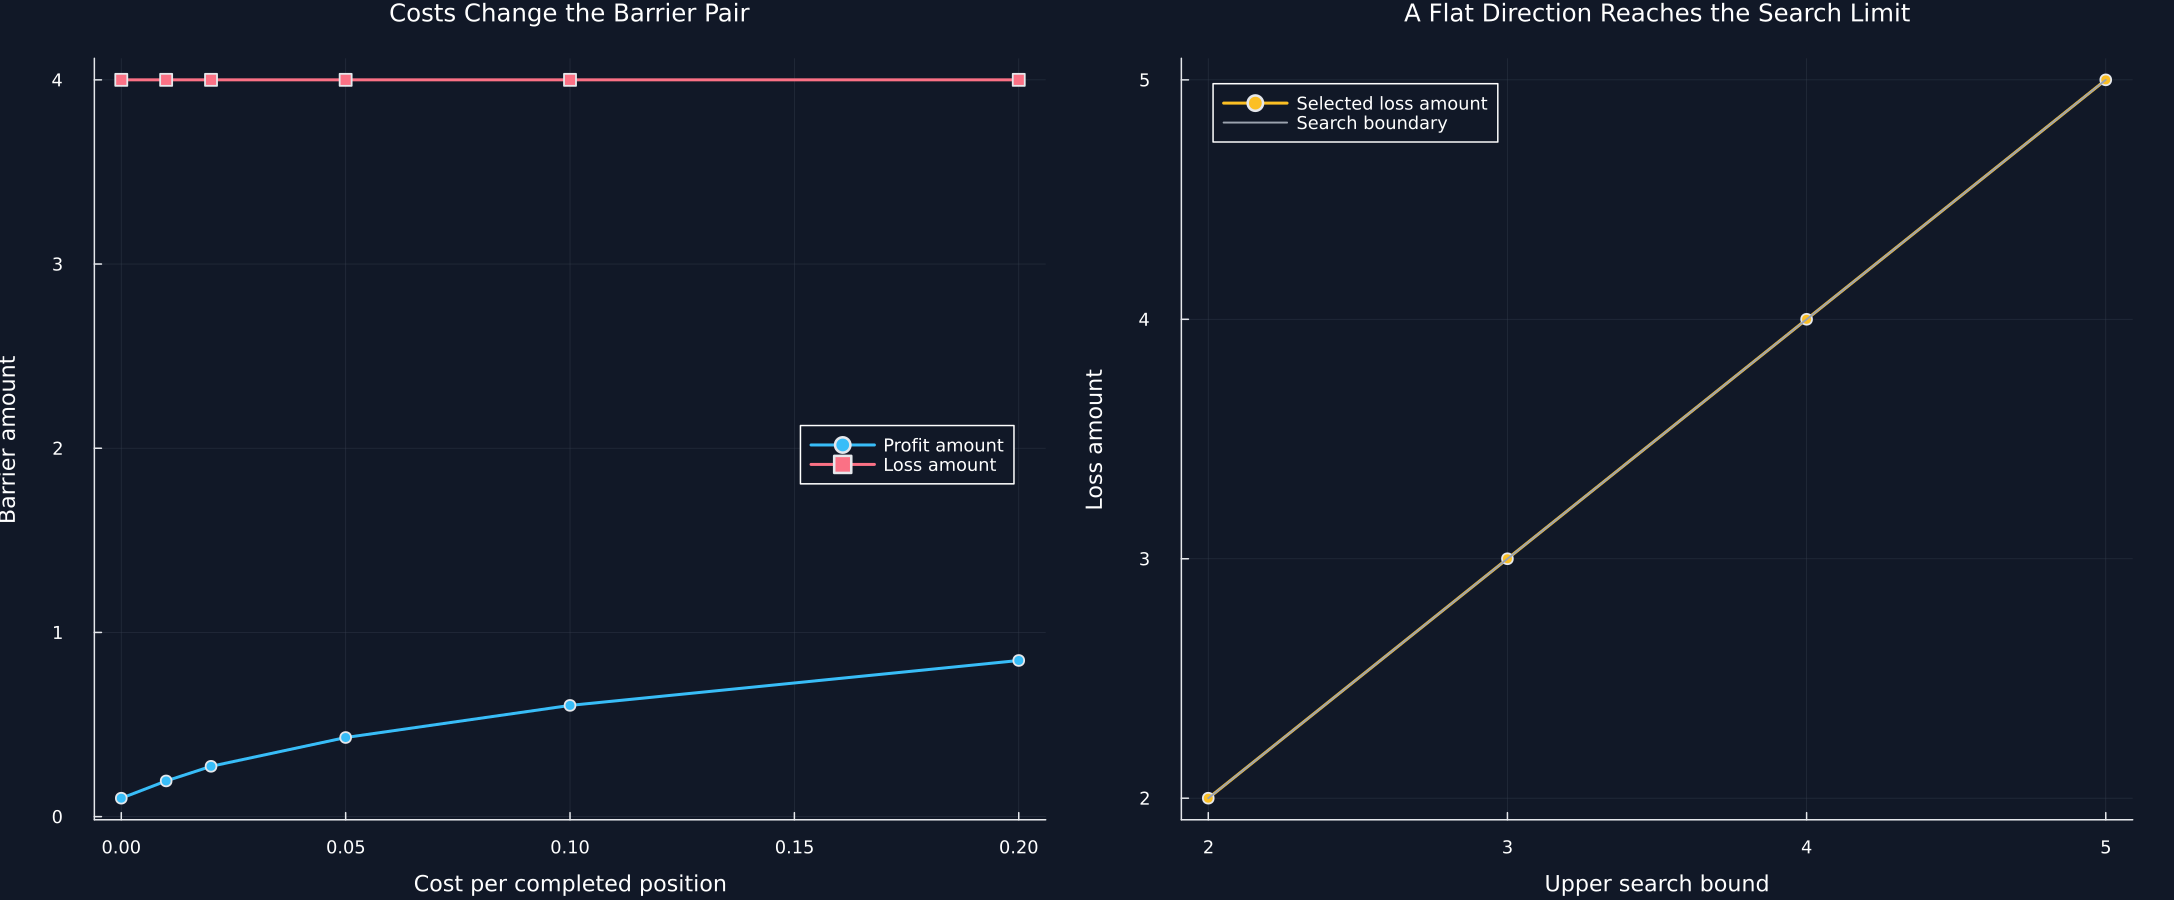

In [5]:
cost_rows = NamedTuple[]
for cost in [0.,.01,.02,.05,.1,.2]
    rule = optimal_ou_trading_rule(public_fit.theta,public_fit.sigma,public_entry_gap;cost,bounds=(.1,4.))
    boundary = any(isclose(value,bound;atol=1e-4) for value in [rule.profit_take,rule.stop_loss],bound in [.1,4.])
    push!(cost_rows,(cost=cost,profit=rule.profit_take,loss=rule.stop_loss,probability=rule.hit_probability,time=rule.expected_holding_time,rate=rule.return_rate,boundary=boundary))
end
cost_sensitivity = DataFrame(cost_rows)
rename!(cost_sensitivity,["Cost","Profit amount","Loss amount","Upper-hit probability","Expected holding time","Expected return per unit time","Touches search boundary"])
boundary_rows = NamedTuple[]
for upper_bound in [2.,3.,4.,5.]
    rule = optimal_ou_trading_rule(public_fit.theta,public_fit.sigma,public_entry_gap;cost=public_cost,bounds=(.1,upper_bound))
    push!(boundary_rows,(bound=upper_bound,profit=rule.profit_take,loss=rule.stop_loss,rate=rule.return_rate,boundary=isclose(rule.stop_loss,upper_bound;atol=1e-4)))
end
boundary_sensitivity = DataFrame(boundary_rows)
rename!(boundary_sensitivity,["Upper search bound","Profit amount","Loss amount","Expected return per unit time","Loss amount at upper bound"])
table(cost_sensitivity,"ou_cost_sensitivity","Public-data barrier choices as the cost changes.")
table(boundary_sensitivity,"ou_boundary_sensitivity","Public-data choices under different search limits.")
p1 = plot(cost_sensitivity[:,1],cost_sensitivity[:,2];marker=:circle,color=palette.cyan,label="Profit amount",title="Costs Change the Barrier Pair",xlabel="Cost per completed position",ylabel="Barrier amount",legend=:right)
plot!(p1,cost_sensitivity[:,1],cost_sensitivity[:,3];marker=:rect,color=palette.rose,label="Loss amount")
p2 = plot(boundary_sensitivity[:,1],boundary_sensitivity[:,3];marker=:circle,color=palette.amber,label="Selected loss amount",title="A Flat Direction Reaches the Search Limit",xlabel="Upper search bound",ylabel="Loss amount",legend=:topleft)
plot!(p2,boundary_sensitivity[:,1],boundary_sensitivity[:,1];color=muted,linewidth=1.3,label="Search boundary")
save_figure(plot(p1,p2;layout=(1,2),size=(1450,600)),paths,"ou_cost_boundary_sensitivity")


## Tests

In [6]:
@assert length(prices)==2330
@assert length(standardized_deviation)==2271
@assert public_fit.theta>0
@assert public_fit.sigma>0
@assert 0<public_fit.rho<1
@assert 0<=public_fit.r2<=1
@assert isclose(public_fit.stationary_std,1.;atol=.02)
controlled_probability = hit_upper_probability(1.,.5,.5,.1,.1)
controlled_time = mean_exit_time(1.,.5,.5,.1,.1)
@assert .5<controlled_probability<=1.
@assert controlled_time>0 && isfinite(controlled_time)
@assert size(preliminary_reproduction)==(15,2)
@assert abs(preliminary_rule.profit_take-preliminary_grid[monte_carlo_location[1]])<=.25+1e-9
@assert preliminary_rule.return_rate>=analytical_surface[analytical_location]-.001
@assert ou_rule_metrics(0.,.5,.1,.1,1.).return_rate==-Inf
@assert ou_rule_metrics(.5,-.1,.1,.1,1.).return_rate==-Inf
recovery_theta = theta_from_half_life(20.)
recovery_path = vec(simulate_ou(recovery_theta,.1,1,6000,1.,primitive("recovery")))
recovery_fit = fit_ornstein_uhlenbeck(recovery_path)
@assert abs(recovery_fit.half_life-20.)<6.
@assert issorted(cost_sensitivity[:,"Expected return per unit time"];rev=true)
@assert sum(boundary_sensitivity[:,"Loss amount at upper bound"])==4
@assert isfile(joinpath(paths.figures,"public_ou_fit.pdf"))
@assert isfile(joinpath(paths.figures,"barrier_probability_holding.pdf"))
@assert isfile(joinpath(paths.figures,"ou_surface_comparison.pdf"))
@assert isfile(joinpath(paths.figures,"ou_cost_boundary_sensitivity.pdf"))
check_summary = DataFrame("Check"=>["Public file identity","Mean-reversion fit","Probability bounds","Positive holding time","Monte Carlo grid agreement","Analytical grid agreement","Known half-life recovery","Cost direction","Boundary contact"],"Status"=>fill("Pass",9))
display(check_summary)


Row,Check,Status
,String,String
1,Public file identity,Pass
2,Mean-reversion fit,Pass
3,Probability bounds,Pass
4,Positive holding time,Pass
5,Monte Carlo grid agreement,Pass
6,Analytical grid agreement,Pass
7,Known half-life recovery,Pass
8,Cost direction,Pass
9,Boundary contact,Pass
